# State of the art: penalised trees, glass-box boosting, monotone boosting and a foundation model against the scorecard

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 70 minutes

## Objectives

By the end of this notebook you can:

- name the current challengers to a WoE scorecard in credit scoring (penalised trees, explainable boosting, monotone gradient boosting, a tabular foundation model), what each one claims and the source of the claim;
- compare them with the scorecard on the same 9,000 held-out cards with the AUC, the paired DeLong test, the Brier score, the calibration error and the chi-square over grades, and recompute the committed comparisons;
- open the glass-box components of the committed models: the rules of the penalised trees and their stability, the shape functions of the boosting machine, and the monotone constraints of the boosted trees;
- read what isotonic calibration did to each challenger, and what changes on a small sample (the 300 German records and a 2,000-row fit), where the foundation model appears.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The comparison reads five committed files of case C01 (retail credit-card PD):

- `data/derived/C01/holdout.json`: the ladder on the 9,000 held-out Taiwan cards (UCI Taiwan, Yeh 2009, CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients): the AUC, the grades, the reliability bins before and after calibration, and the battery of tests.
- `data/derived/C01/models-taiwan.json`: what each model learned (rules, shape functions, constraints, calibration maps).
- `data/derived/C01/small-sample.json`: the same cards scored by models fitted on only 2,000 rows.
- `data/derived/C01/german-twin.json` and `data/derived/C01/models-german.json`: the Statlog German credit data (1,000 records, UCI, CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data), with a holdout of 300, where the foundation model P5 is also present.

Everything is read, nothing is refitted: the challengers need `interpret`, `lightgbm`, `xgboost` (and `tabpfn` for P5) besides `scikit-learn`, and the notebook environment does not carry them (it has `scikit-learn`, for the references of topic 13, but not the rest); their versions are those recorded in the committed fit. The next cell loads the files and prints the ladder with each model's engine, version and licence.

In [2]:
# Load the committed files and print the ladder with each model's engine, version and licence
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
read = lambda name: json.loads((derived / name).read_text(encoding="utf-8"))
holdout, models, small, german_twin, models_german = (read(n) for n in ("holdout.json", "models-taiwan.json", "small-sample.json", "german-twin.json", "models-german.json"))

LANG = "en"
# The engine's light values, named in this language
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
for m in models["model"]:
    print(f"{m['id']:14s} {m['engine_version'][:36]:36s} {m['licence'][:40]}")
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)


P0-constant    n/a                                  MIT
P0-single      1.0.0                                Apache-2.0
P1-scorecard   optbinning 1.0.0, statsmodels 0.15.0 Apache-2.0, BSD-3-Clause
P2a-l1         1.9.1                                BSD-3-Clause
P2b-pltr       1.9.1                                BSD-3-Clause
P3-ebm         0.7.8                                MIT
P4-lightgbm    4.7.0                                MIT
P4-xgboost     3.4.1                                Apache-2.0
baked by riskvalidation 0.4.3 | installed 0.9.0


## Method

### The protocol of the comparison

Every challenger is judged on the same 9,000 cards by the same battery, so that a difference is a property of the model and not of the sample. Three measurements decide, and each has its own tool in the engine:

- **ranking**: the AUC, and for two models scored on the same cards the paired DeLong test of notebook 03, whose z statistic is the AUC difference over its standard error (DeLong, DeLong and Clarke-Pearson, 1988);
- **the quality of the forecast**: the Brier score, the mean squared error of the PD as a forecast of the 0/1 outcome, and the expected calibration error over $B$ bins, $\mathrm{ECE} = \sum_b (n_b/N)\,|\overline{\mathrm{PD}}_b - \mathrm{DR}_b|$, the weighted mean gap between the mean PD and the observed default rate of a bin;
- **the fit by grade**: the chi-square over the grades of the master scale (BCBS Working Paper 14), which the engine computes from the counts, defaults and mean PD of each grade.

The next cell checks the ECE formula on the committed reliability bins of the scorecard, against the engine's committed value, and then calls the engine's chi-square over grades on the committed grade table of every model and compares it with the committed row. Then it prints the common table of the ladder: AUC, the paired comparison with the scorecard, Brier, ECE and the chi-square p-value.

In [3]:
# Check the ECE formula, call the engine's chi-square over grades on every model and print the common table of the ladder
from riskvalidation.validation import pd_chi2_grades

policy = rv.default_policy()
tests = holdout["tests"]


def row(test_id, model_id, doc=holdout, segment="portfolio"):
    return next((t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == segment), None)


def ece_of(bins_):
    total = sum(b["n"] for b in bins_)
    return sum(b["n"] * abs(b["pd"] - b["dr"]) for b in bins_) / total


p1_bins = holdout["outputs"]["rungs"]["P1-scorecard"]["reliability"]
print("ECE from the bins of the scorecard:", round(ece_of(p1_bins), 6), "| committed:", round(row("pd.ece", "P1-scorecard")["metric"], 6))
print()
rungs = [m["id"] for m in holdout["model"]]
print(f"{'model':14s} {'AUC':>7s} {'z vs P1':>9s} {'p DeLong':>10s} {'Brier':>7s} {'ECE':>7s} {'p chi2 engine':>16s} {'committed':>10s} {'light':>6s}")
for r in rungs:
    grades = [g for g in holdout["outputs"]["rungs"][r]["grades"] if g["n"] > 0]
    chi = pd_chi2_grades([g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades], policy=policy, model_id=r, segment="portfolio")
    chi_row = row("pd.chi2_grades", r)
    dl = row("disc.delong", r)
    z = "-" if dl is None else f"{dl['statistic']:.2f}"
    p_dl = "-" if dl is None else f"{dl['p_value']:.3g}"
    committed_p = "-" if chi_row is None else f"{chi_row['p_value']:.3g}"
    light_text = "-" if chi_row is None else LIGHT[chi_row["light"]]
    print(f"{r:14s} {row('disc.auc', r)['metric']:7.4f} {z:>9s} {p_dl:>10s} {row('pd.brier', r)['metric']:7.4f} {row('pd.ece', r)['metric']:7.4f} {chi.p_value:16.3g} {committed_p:>10s} {light_text:>6s}")


ECE from the bins of the scorecard: 0.015501 | committed: 0.015501

model              AUC   z vs P1   p DeLong   Brier     ECE    p chi2 engine  committed  light
P0-constant     0.5000         -          -  0.1723  0.0174            0.994          -      -
P0-single       0.6917    -13.35   1.26e-40  0.1431  0.0144            0.598      0.598  green
P1-scorecard    0.7587         -          -  0.1393  0.0155           0.0264     0.0264  amber
P2a-l1          0.7587     -1.70     0.0884  0.1393  0.0153           0.0405     0.0405  amber
P2b-pltr        0.7749      6.67   2.58e-11  0.1367  0.0113            0.464      0.464  green
P3-ebm          0.7746      6.31   2.74e-10  0.1367  0.0118                0          0    red
P4-lightgbm     0.7770      7.19   6.53e-13  0.1361  0.0134         0.000672   0.000672    red
P4-xgboost      0.7755      7.02   2.18e-12  0.1359  0.0124                0          0    red


## State of the art

### The benchmark evidence

The research of this product (dossier 04, section B.4) read the credit-scoring benchmarks. Four findings frame the comparison; each carries its source:

| Source | Design | Finding relevant here |
|---|---|---|
| Baesens et al. (2003), https://doi.org/10.1057/palgrave.jors.2601545 | 8 real credit datasets, AUC and accuracy with significance tests | support-vector machines and neural networks perform very well, and simple logistic regression and linear discriminant analysis also perform very well |
| Lessmann, Baesens, Seow and Thomas (2015), https://doi.org/10.1016/j.ejor.2015.05.030 | 41 classifiers, 8 retail datasets, six measures | several classifiers beat logistic regression significantly, especially heterogeneous ensembles; random forest is the recommended minimum benchmark; report at least the AUC, the partial Gini and the Brier score |
| Gunnarsson et al. (2021), https://doi.org/10.1016/j.ejor.2021.03.006 | multilayer perceptron and deep belief network against logistic regression, trees, random forest and XGBoost | XGBoost is the best method, and deep networks do not outperform shallower counterparts |
| Grinsztajn, Oyallon and Varoquaux (2022), https://arxiv.org/abs/2207.08815 | 45 general tabular datasets (not credit-specific) | tree-based models remain state of the art on medium-sized data of about 10,000 samples |

The synthesis the research drew, and the product's ladder follows: tree ensembles beat plain logistic regression on most retail benchmarks, by a few AUC points; logistic regression on well-binned WoE stays competitive; interpretability can be recovered with constrained or glass-box models, which are the natural challengers of a regulated PD model; and calibration is a property separate from discrimination. The next cell lines up the committed AUC of every rung with the gain over the scorecard, its 95% interval and the paired DeLong p-value, and the figure draws it.

model              AUC     95% interval     gain vs P1   p DeLong
P0-constant     0.5000   0.500-0.500        -0.2587          -
P0-single       0.6917   0.679-0.705        -0.0670   1.26e-40
P1-scorecard    0.7587   0.746-0.771        +0.0000          -
P2a-l1          0.7587   0.746-0.771        -0.0000     0.0884
P2b-pltr        0.7749   0.763-0.787        +0.0162   2.58e-11
P3-ebm          0.7746   0.763-0.787        +0.0159   2.74e-10
P4-lightgbm     0.7770   0.765-0.789        +0.0183   6.53e-13
P4-xgboost      0.7755   0.763-0.787        +0.0168   2.18e-12


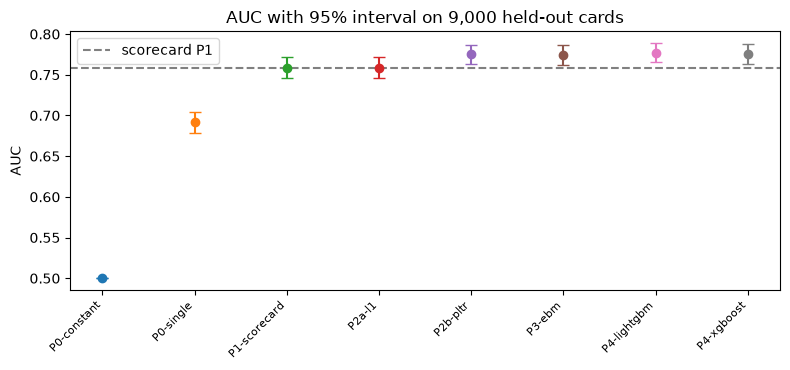

In [4]:
# Line up the AUC of every rung with its gain over the scorecard and the paired DeLong p-value, and draw it
base = row("disc.auc", "P1-scorecard")["metric"]
print(f"{'model':14s} {'AUC':>7s} {'95% interval':>16s} {'gain vs P1':>14s} {'p DeLong':>10s}")
for r in rungs:
    a = row("disc.auc", r)
    dl = row("disc.delong", r)
    p_text = "-" if dl is None else f"{dl['p_value']:.3g}"
    print(f"{r:14s} {a['metric']:7.4f} {a['extras']['ci95_low']:7.3f}-{a['extras']['ci95_high']:.3f} {a['metric'] - base:+14.4f} {p_text:>10s}")

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, r in enumerate(rungs):
    a = row("disc.auc", r)
    ax.errorbar(i, a["metric"], yerr=[[a["metric"] - a["extras"]["ci95_low"]], [a["extras"]["ci95_high"] - a["metric"]]], fmt="o", capsize=4)
ax.axhline(base, color="gray", linestyle="--", label="scorecard P1")
ax.set_xticks(range(len(rungs)))
ax.set_xticklabels(rungs, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC")
ax.set_title("AUC with 95% interval on 9,000 held-out cards")
ax.legend()
fig.tight_layout()
plt.show()


### Penalised trees (PLTR) and the penalised logistic regression

Dumitrescu, Hue, Hurlin and Tokpavi (2022, https://doi.org/10.1016/j.ejor.2021.06.053) propose the **penalised logistic tree regression**: short decision trees are grown, each root-to-node path becomes a binary rule (such as "`PAY_0 <= 1.5`"), and the rules enter a logistic regression with an L1 penalty that keeps few of them. The research summary reports that it significantly beats logistic regression and is competitive with a random forest while keeping the readability of a logistic model. The product's rung P2b follows that design with scikit-learn trees and `LogisticRegression`, with its own rule extraction; rung P2a is the plain L1 logistic regression on the WoE variables. The next cell reads what the committed fits kept: how many candidate rules P2b generated and how many survived the penalty, its first rules with their coefficients, and the stability of the rule set across 20 bootstrap resamples (the mean Jaccard index of the selected rule sets, 1 for identical sets), together with the coefficients of P2a against those of the scorecard.

In [5]:
# Read the rules kept by P2b, their stability across bootstraps, and the coefficients of P2a against the scorecard
details = {m["id"]: m["details"] for m in models["model"]}
pltr = details["P2b-pltr"]
print("candidate rules:", pltr["n_candidate_rules"], "| rules kept by the L1 penalty:", len(pltr["selected_rules"]))
for rule in pltr["selected_rules"][:6]:
    print(f"  {rule['coefficient']:8.3f}  {rule['rule']}")
st = pltr["stability"]
print("Jaccard index of the selected sets over", st["bootstraps"], "bootstraps: mean", round(st["jaccard_mean"], 3), "| minimum", round(st["jaccard_min"], 3))
l1, card = details["P2a-l1"], details["P1-scorecard"]
gap = max(abs(l1["coefficients"][v] - card["coefficients"][v]) for v in card["features"])
print("P2a: variables kept", len(l1["selected"]), "| signs agree with the WoE:", l1["signs_agree_with_woe"], "| largest coefficient gap with the scorecard:", round(gap, 4))


candidate rules: 449 | rules kept by the L1 penalty: 101
     0.302  LIMIT_BAL <= 145000
    -1.270  PAY_0 <= 1.5
     0.035  BILL_AMT5 <= 50602
     0.023  PAY_AMT5 <= 2926.5
     0.108  PAY_AMT6 <= 2305.5
     0.147  LIMIT_BAL <= 145000 and LIMIT_BAL <= 45000
Jaccard index of the selected sets over 20 bootstraps: mean 0.411 | minimum 0.367
P2a: variables kept 13 | signs agree with the WoE: True | largest coefficient gap with the scorecard: 0.0019


### Explainable boosting (EBM and GA2M)

The generalised additive model with pairwise interactions (GA2M, Lou, Caruana, Gehrke and Hooker, 2013, https://doi.org/10.1145/2487575.2487579) and its boosted implementation, the explainable boosting machine (Nori, Jenkins, Koch and Caruana, 2019, https://arxiv.org/abs/1909.09223), model the log-odds as a sum of one-variable functions and a few pairwise terms:

$$g(\mathbb{E}[y]) = \beta_0 + \sum_j f_j(x_j) + \sum_{(i,j)} f_{ij}(x_i, x_j)$$

with $g$ the logit link and each $f_j$ learned by cyclic gradient boosting with a very low learning rate. The research summary notes the consequence for credit: an EBM is a boosted scorecard, since each $f_j$ can be read as a points table and the reason codes of the main effects are exact. The committed fit exports the terms. The next cell reads the shape function of the credit limit and of the latest repayment status from the export, and puts them next to the scorecard's own contribution to the log-odds in the same bins, $\beta_j\,\mathrm{WoE}_{j,b}$ (notebook 01). Both are shifted so that their lowest level is zero, because the additive constants live in the intercept.

main-effect terms: 20 | pairwise terms: 5 | ['BILL_AMT1 & BILL_AMT2', 'BILL_AMT1 & BILL_AMT3'] ...


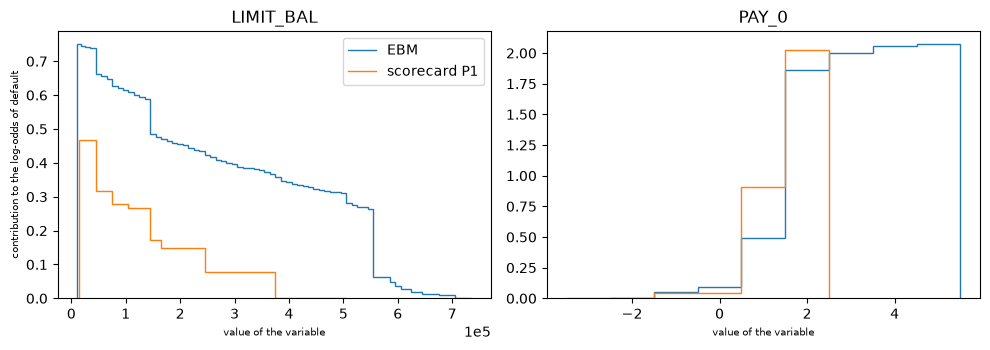

PAY_0 EBM levels: [-0.32, -0.26, -0.23, 0.18, 1.55, 1.68, 1.74, 1.76]
PAY_0 scorecard: [-0.47, -0.43, 0.43, 1.55]


In [6]:
# Read two shape functions of the EBM export and compare them with the scorecard's contribution in its own bins
export = details["P3-ebm"]["export"]
term_names = [t["name"] for t in export["terms"]]
main_terms = [t for t in export["terms"] if len(t["features"]) == 1]
pair_terms = [t for t in export["terms"] if len(t["features"]) == 2]
print("main-effect terms:", len(main_terms), "| pairwise terms:", len(pair_terms), "|", [t["name"] for t in pair_terms][:2], "...")


def ebm_steps(name):
    # The interval of each score is between two cut points; the first and last scores are the missing and unseen bins
    term = next(t for t in main_terms if t["name"] == name)
    cuts = next(f for f in export["features"] if f["name"] == name)["levels"][0]["cuts"]
    return np.array(cuts), np.array(term["scores"][1:-1])


def card_steps(name):
    rows = [r for r in card["points_table"] if r["feature"] == name and r["count"] > 0]
    return np.array(card["bins"][name]["splits"]), np.array([card["coefficients"][name] * r["woe"] for r in rows])


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    cuts_e, scores_e = ebm_steps(name)
    cuts_c, scores_c = card_steps(name)
    for cuts_, scores_, label in ((cuts_e, scores_e, "EBM"), (cuts_c, scores_c, "scorecard P1")):
        # One value per interval: the edges are the cut points plus one outer edge on each side
        edges = np.r_[cuts_[0] - (cuts_[1] - cuts_[0]) if len(cuts_) > 1 else cuts_[0] - 1, cuts_, cuts_[-1] + (cuts_[-1] - cuts_[-2]) if len(cuts_) > 1 else cuts_[-1] + 1]
        ax.stairs(scores_ - scores_.min(), edges, label=label)
    ax.set_title(name)
    ax.set_xlabel("value of the variable", fontsize=7)
    if name == "LIMIT_BAL":
        ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set_ylabel("contribution to the log-odds of default", fontsize=7)
axes[0].legend()
fig.tight_layout()
plt.show()
print("PAY_0 EBM levels:", [round(float(s), 2) for s in ebm_steps("PAY_0")[1]])
print("PAY_0 scorecard:", [round(float(s), 2) for s in card_steps("PAY_0")[1]])


### Monotone gradient boosting

Gradient-boosted trees (LightGBM, XGBoost, CatBoost) accept a monotone constraint per variable, the same direction the scorecard imposes by its binning. The documentation of each engine states the caveats the research recorded: with the `hist` or `approx` tree methods XGBoost constraints can wipe out split candidates and give shallow trees (https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html); LightGBM offers the methods `basic`, `intermediate` and `advanced`, of which `basic` over-constrains the predictions (https://lightgbm.readthedocs.io/en/latest/Parameters.html); and the `monotonize()` of the EBM is applied after the fit, to one term at a time. The committed LightGBM fit uses the `advanced` method with the same constraints as the scorecard, and the artifact stores a check: the partial-dependence curve of the model along a grid of each constrained variable, with the largest violation of the constraint found. The next cell compares the committed constraints with the scorecard's, prints the violations, and draws the curves of two variables.

constraints equal the scorecard's: True | method: advanced | trees: 94
variables checked: 13 | largest violation found: 0.0 | monotone: True


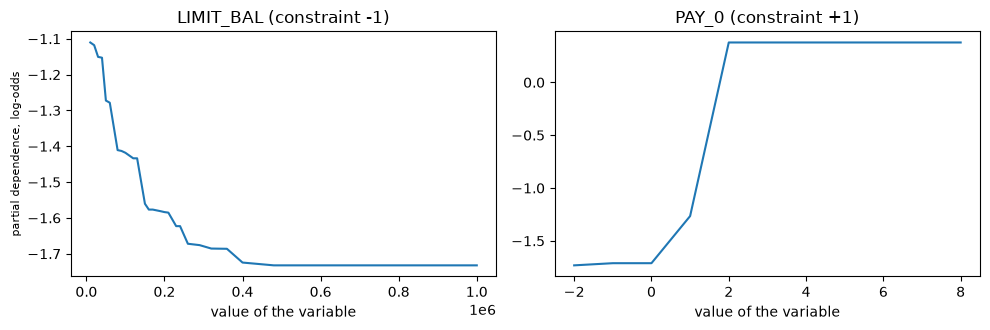

In [7]:
# Compare the committed constraints with the scorecard's, print the violations and draw two partial-dependence curves
lgbm = details["P4-lightgbm"]
scorecard_directions = {v["name"]: v["monotone"] for v in models["fit"]["features"]}
same = all(lgbm["constraints"][k] == scorecard_directions[k] for k in scorecard_directions)
print("constraints equal the scorecard's:", same, "| method:", lgbm["params"]["monotone_constraints_method"], "| trees:", lgbm["rounds"])
check = lgbm["monotonicity"]
print("variables checked:", len(check["features"]), "| largest violation found:", max(f["max_violation"] for f in check["features"].values()), "| monotone:", check["monotone"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    f = check["features"][name]
    ax.plot(f["grid"], f["pdp"])
    ax.set_title(f"{name} (constraint {f['direction']:+d})")
    ax.set_xlabel("value of the variable")
axes[0].set_ylabel("partial dependence, log-odds", fontsize=8)
fig.tight_layout()
plt.show()


### Calibration after the ranking

Discrimination and calibration are separate properties: a model can rank well and give PDs of the wrong size. Two warnings from the research apply. Correcting a class imbalance by resampling (random under- or over-sampling, SMOTE) produces strongly miscalibrated models, with the minority-class probability over-estimated, without a higher AUC (van den Goorbergh, van Smeden, Timmerman and Van Calster, 2022, https://doi.org/10.1093/jamia/ocac093); when a sample is balanced by design, the intercept must be corrected for the prior (King and Zeng, 2001, https://doi.org/10.1093/oxfordjournals.pan.a004868). C01 resamples nothing: its default rate is 22%, and the challengers keep the training distribution. What the product does is fit a **post-hoc calibration map** on a slice of cards that neither the fit nor the test has seen, the isotonic regression (Zadrozny and Elkan, 2002, https://doi.org/10.1145/775047.775151), a monotone step function that cannot reorder the cards. The reliability bins of the artifact are stored before the map (`reliability_raw`) and after it (`reliability`), so its effect can be measured with the ECE formula checked above.

In [8]:
# Measure the ECE of the challengers before and after the isotonic map, from the stored reliability bins
print(f"{'model':14s} {'map':>10s} {'fitted on':>22s} {'ECE before':>12s} {'ECE after':>12s} {'committed ECE':>16s}")
for m in models["model"]:
    if m["calibration"] is None:
        continue
    r = m["id"]
    rung_bins = holdout["outputs"]["rungs"][r]
    print(f"{r:14s} {m['calibration']['kind']:>10s} {'calibration slice':>22s} {ece_of(rung_bins['reliability_raw']):12.4f} {ece_of(rung_bins['reliability']):12.4f} {row('pd.ece', r)['metric']:16.4f}")
print("points of the isotonic map of P3:", len(next(m for m in models["model"] if m["id"] == "P3-ebm")["calibration"]["x"]))


model                 map              fitted on   ECE before    ECE after    committed ECE
P3-ebm           isotonic      calibration slice       0.0218       0.0118           0.0118
P4-lightgbm      isotonic      calibration slice       0.0121       0.0134           0.0134
P4-xgboost       isotonic      calibration slice       0.0131       0.0124           0.0124
points of the isotonic map of P3: 58


### Small data and the foundation model

Tabular foundation models are the open frontier of the research, strongest on small data (Hollmann et al., 2025, https://doi.org/10.1038/s41586-024-08328-6): TabPFN predicts by in-context learning and trains nothing per dataset. Its licence is part of the evidence. According to the research (read from the project's README, https://github.com/PriorLabs/TabPFN, on 2026-10-04), the code is Apache-2.0 while the weights are licensed per version: those of v2 under the Prior Labs License v1.1 (Apache 2.0 plus an attribution clause), those of the later versions under a non-commercial licence that allows research and internal benchmarking but not production use. The product therefore carries it as an optional **research challenger** (rung P5), present only where its extra is installed. The credit-specific evidence found is a conference abstract with preliminary results and no numbers (UNVERIFIED beyond the abstract). The committed German twin has 1,000 records and a holdout of 300, the small-data case. The next cell prints the committed licence of P5, and for the 300 German records and for the 9,000 Taiwan cards scored by models fitted on 2,000 rows, the AUC of each rung with the paired DeLong p-value against the scorecard and the light of Hosmer-Lemeshow.

In [9]:
# Print the licence of P5 and the small-data comparisons: 300 German records and models fitted on 2,000 rows
p5 = next(m for m in models_german["model"] if m["id"] == "P5-tabpfn")
assert "Apache-2.0" in p5["licence"] and "Prior Labs License v1.1" in p5["licence"]
print("P5 engine:", p5["engine"], p5["engine_version"], "| code licence: Apache-2.0 | weights: TabPFN v2, Prior Labs License v1.1 (attribution required)")
for title, doc in (("German twin, holdout of 300 records", german_twin), ("Taiwan cards, models fitted on 2000 rows", small)):
    print()
    print(title, "|", doc["outputs"]["n"], "cards, defaults", doc["outputs"]["defaults"])
    print(f"{'model':14s} {'AUC':>7s} {'p DeLong':>10s} {'p HL':>10s} {'light HL':>10s}")
    for m in doc["model"]:
        r = m["id"]
        if r in ("P0-constant",):
            continue
        a = row("disc.auc", r, doc)
        dl = row("disc.delong", r, doc)
        hl = row("pd.hosmer_lemeshow", r, doc)
        print(f"{r:14s} {a['metric']:7.4f} {'-' if dl is None else format(dl['p_value'], '.3g'):>10s} {format(hl['p_value'], '.3g'):>10s} {LIGHT[hl['light']]:>10s}")


P5 engine: tabpfn 9.1.0 | code licence: Apache-2.0 | weights: TabPFN v2, Prior Labs License v1.1 (attribution required)

German twin, holdout of 300 records | 300 cards, defaults 90
model              AUC   p DeLong       p HL   light HL
P0-single       0.7233     0.0189      0.328      green
P1-scorecard    0.7883          -      0.876      green
P2a-l1          0.7908      0.124      0.654      green
P2b-pltr        0.7861       0.87      0.597      green
P3-ebm          0.7874      0.955   4.11e-14        red
P4-lightgbm     0.7784      0.615          0        red
P5-tabpfn       0.7769      0.488          0        red

Taiwan cards, models fitted on 2000 rows | 9000 cards, defaults 1991
model              AUC   p DeLong       p HL   light HL
P0-single       0.6928   5.33e-38      0.101      green
P1-scorecard    0.7525          -    3.5e-05        red
P2a-l1          0.7511     0.0737     0.0097        red
P2b-pltr        0.7528      0.936   1.27e-21        red
P3-ebm          0.76

## Results

- **On 9,000 Taiwan cards the richer models rank better, by a few AUC points.** The monotone boosted trees reach 0.777 (LightGBM) and 0.775 (XGBoost) against 0.759 for the scorecard, the penalised trees and the boosting machine 0.775; the paired DeLong p-value is below 1e-9 for the four, and the penalised logistic regression ties the scorecard (p 0.09). That is the size the benchmarks reported (a few points): a gain of 0.016 to 0.018 AUC points.
- **Fit by grade does not follow the ranking.** The chi-square over grades is red for the boosting machine and the two boosted rungs and amber for the scorecard and P2a, while the penalised trees are green. The engine returns the committed p-value from each grade table. A better ranker is not a better calibrated one.
- **The glass boxes open.** The penalised trees kept 101 of 449 candidate rules, but the rule set is unstable across bootstraps (mean Jaccard about 0.41), which limits how much a reader can lean on any one rule. The explainable boosting machine's shape functions for the credit limit and the repayment status have the same direction and a similar stepped shape as the scorecard's contributions, and its 5 pairwise terms are all among the bill amounts. The boosted trees obey their monotone constraints: the checks stored with the fit find no violation.
- **Calibration helps when it is needed.** The isotonic map halves the ECE of the boosting machine (0.022 to 0.012), changes the boosted trees by about a thousandth (0.012 to 0.013 for LightGBM, a slight worsening), and cannot reorder cards. A calibration map is a tool, not a guarantee, and its effect is measured, not assumed.
- **On small data the advantage disappears.** On the 300 German records no challenger beats the scorecard significantly (DeLong p from 0.12 to 0.96, and 0.61 for LightGBM); the foundation model P5 reaches an AUC of 0.777 against 0.788 for the scorecard, with the lowest ECE of the ladder (0.039 against 0.045), and the boosting machine, LightGBM and P5 are red on Hosmer-Lemeshow. With models fitted on 2,000 rows the boosting machine does beat the scorecard (p 0.0005), a gain of 0.012 AUC points.

What this notebook does not show: the fitting of the challengers (`data-pipeline/pipeline/model/` of the product, with the libraries pinned in `data-pipeline/requirements.txt`), a head-to-head with a random forest (the research recommends it as a minimum benchmark; the ladder has no random forest rung), or any out-of-time evidence: C01 is a single snapshot, and notebook 04 is where the out-of-time design is shown. The credit-specific TabPFN evidence is a preliminary abstract; the German twin is a single dataset of 300 holdout records, and 90 defaults leave wide intervals.

## Summary

- The research of this product found that tree ensembles beat a plain logistic regression by a few AUC points on retail credit, that glass-box variants recover interpretability, that calibration is a separate property, and that tabular foundation models are strongest on small data under licence restrictions; the committed ladder reproduces each of those statements on its own data.
- The paired DeLong test, the Brier score, the ECE and the chi-square over grades put every challenger on the same footing as the scorecard, and each can be recomputed from the committed tables.
- The glass boxes can be read: rules and their stability, shape functions beside the scorecard's contributions, constraints and the stored check that the monotonicity holds.
- An isotonic calibration map is measured, not assumed, and on small data the ranking advantage of the challengers is not significant.

**What to try next.** Pick the rung with the largest gain and read its grade table in `holdout.json` against the scorecard's, then continue with notebook 07, which shows how the splits that make these comparisons fair are enforced.

## References

- Baesens, B., Van Gestel, T., Viaene, S., Stepanova, M., Suykens, J. and Vanthienen, J. (2003), Journal of the Operational Research Society 54(6). https://doi.org/10.1057/palgrave.jors.2601545
- Lessmann, S., Baesens, B., Seow, H.-V. and Thomas, L. C. (2015), European Journal of Operational Research 247(1). https://doi.org/10.1016/j.ejor.2015.05.030
- Gunnarsson, B. R., vanden Broucke, S., Baesens, B., Oskarsdottir, M. and Lemahieu, W. (2021), Deep learning for credit scoring: do or don't?, European Journal of Operational Research 295(1). https://doi.org/10.1016/j.ejor.2021.03.006
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022), Why do tree-based models still outperform deep learning on typical tabular data?, NeurIPS 2022 Datasets and Benchmarks. https://arxiv.org/abs/2207.08815
- Dumitrescu, E., Hue, S., Hurlin, C. and Tokpavi, S. (2022), penalised logistic tree regression, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.053
- Lou, Y., Caruana, R., Gehrke, J. and Hooker, G. (2013), Accurate intelligible models with pairwise interactions, KDD 2013. https://doi.org/10.1145/2487575.2487579
- Nori, H., Jenkins, S., Koch, P. and Caruana, R. (2019), InterpretML: a unified framework for machine learning interpretability. https://arxiv.org/abs/1909.09223
- van den Goorbergh, R., van Smeden, M., Timmerman, D. and Van Calster, B. (2022), The harm of class imbalance corrections for risk prediction models, JAMIA 29(9). https://doi.org/10.1093/jamia/ocac093
- King, G. and Zeng, L. (2001), Logistic regression in rare events data, Political Analysis 9(2). https://doi.org/10.1093/oxfordjournals.pan.a004868
- Zadrozny, B. and Elkan, C. (2002), Transforming classifier scores into accurate multiclass probability estimates, KDD 2002. https://doi.org/10.1145/775047.775151
- Hollmann, N. et al. (2025), Accurate predictions on small data with a tabular foundation model, Nature 637. https://doi.org/10.1038/s41586-024-08328-6 ; the weights licences are those of the project README, https://github.com/PriorLabs/TabPFN
- XGBoost documentation, monotonic constraints. https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html ; LightGBM documentation, parameters. https://lightgbm.readthedocs.io/en/latest/Parameters.html
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves, Biometrics 44(3). https://doi.org/10.2307/2531595
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Statlog German Credit Data, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data